# 1. Власне донавчання


#### Підготовка середвоища

Для виконання власного донавчення моделі потрібно імпортувати бібліотеки.
* **`transformers`, `trl`, `peft`, `accelerate`** - для роботи з моделями Hugging Face та донавчання (LoRa, QLoRa).
* Також видаляємо вбудовану в Colab бібліотеку `torchao`, тому що її стара версія конфілктує з новими версіями `peft`.

In [13]:
!pip install -q "transformers>=4.55.0" "trl>=1.17" "peft" "datasets" "accelerate"
!pip uninstall -q -y torchao

Імпортуємо встановлені бібліотеки та фіксуємо `seed`.

Фіксація `seed` потрібна для того, щоб усі випадкові процеси були відтворюваними під час кожного запуску ноутбука.

In [14]:
import gc
import json
import random
import torch
import pandas as pd
from huggingface_hub import notebook_login
import re
import time
from datasets import Dataset, load_dataset
import matplotlib.pyplot as plt
from transformers import AutoModelForCausalLM, AutoTokenizer, set_seed

set_seed(42)
random.seed(42)

Донавчання LLM вимагає суттєвих обчислювальних ресурсів, тому треба увімкнути апаратний прискорювач GPU.

Перевіряємо, чи підключений GPU і скільки пам'яті доступно.

In [15]:
assert torch.cuda.is_available(), "Для цього ноутбука потрібна GPU!"

device_name = torch.cuda.get_device_name()
total_memory = torch.cuda.get_device_properties(0).total_memory / 1e9

print(f"Пристрій: {device_name}")
print(f"Памʼять GPU: {total_memory:.1f} GB")

Пристрій: Tesla T4
Памʼять GPU: 15.6 GB


## 1.1. Задача

**Опис задачі: ШІ-критик SQL-запитів**

Задача полягає у створенні ШІ-асистента, який автоматично перевіряє оптимізовані SQL-запити на семантичну еквівалентність їхнім оригінальним версіям.

*   **Користувач:** Розробники баз даних, бекенд-розробники або аналітики даних, які рефакторять та оптимізують складні SQL-запити.
*   **Вхідні дані:** Модель отримує DDL-схему бази даних, оригінальний SQL-запит та новий, оптимізований SQL-запит.
*   **Вихідні дані:** Модель має повернути відповідь у строгому JSON-форматі: булеве значення чи еквівалентні запити та короткий опис помилки, якщо оптимізований запит зламав логіку.

**Чому потрібне саме донавчання?**

1.  **Суворий формат (JSON):** Базові малі моделі або моделі без донавчання через промпт часто збиваються і замість чистого JSON починають генерувати зайвий текст. Донавчання SFT гарантує, що модель завжди віддаватиме лише валідний JSON.
2.  **Специфіка завдання:** RAG тут не допоможе, оскільки нам не потрібно шукати зовнішню інформацію в базі знань. Завдання вимагає специфічної логіки порівняння двох запитів на основі схеми, що важко пояснити системним промптом так, щоб мала модель стабільно його виконувала. Моделі потрібно показати сотні прикладів правильної поведінки.

**Вибір методу донавчання**

Обрано **Supervised Fine-Tuning (SFT)**. Саме SFT найкраще підходить для навчання моделі відповідати у заданому форматі та виконувати роль асистента. Оскільки тренування відбувається на безкоштовному GPU T4, SFT комбінується з адаптерами LoRA.
Застосування QLoRA не є доцільним, оскільки обрана модель невелика, що пояснюється у наступних розділах, і в базовому 16-бітному форматі разом з активаціями споживає лише 5–6 ГБ VRAM, що легко вміщується у 15 ГБ ліміту відеокарти T4. Використання QLoRA лише непотрібно сповільнило б процес навчання через додаткові витрати часу на деквантизацію ваг на льоту під час кожного кроку, не давши жодних переваг.

## 1.2. Модель і дані

#### Для створення ШІ-критика SQL-запитів було обрано модель **`Qwen/Qwen2.5-1.5B-Instruct`**.

**Чому `Instruct`, а не `Base`?**

Завдання вимагає від моделі видавати відповідь у форматі JSON. Базові моделі призначені для догенерування тексту і не здатні чітко слідувати інструкціям та вказівкам, які задаються системним промптом. А Instruct версія навчена працювати як асистент і виконувати поставлену задачу.

---

**Чому розмір саме 1.5B параметрів?**

Безкоштовне середовище Google Colab з GPU T4 має обмеження у 15 ГБ графічної пам'яті. Модель завантажується у 16-бітному форматі, тому її ваги займають:

`1.5 млрд параметрів × 2 байти = 3 ГБ`.

У разі використання більшої моделі, наприклад, Qwen на 4B, лише її ваги зайняли б 8 ГБ. Проте під час тренування пам'ять витрачається не лише на статичні ваги, а й на динамічні обчислення:

- **Базові витрати:** CUDA/PyTorch резервує близько 1 ГБ для ініціалізації.
- **LoRA та оптимізатор:** Треновані параметри адаптера та стани оптимізатора забирають ще близько 200 МБ.
- **Активації:** Максимальний промпт із DDL-схемою сягає 667 токенів (ліміт 1024). Пам'ять під проміжні обчислення залежить від архітектури, у Qwen 1.5B це 28 шарів, 12 голів уваги. Для батча 2 матриці уваги займають:

`2 розмірБатча × 12 голів × 1024² токени × 2 байти × 28 шарів = 1.4 ГБ`.

Збереження станів MLP, ембедингів та нормалізації додає ще 1-1.5 ГБ. Загалом це 2.5-3 ГБ, але завдяки увімкненому `gradient_checkpointing=True` активації перераховуються на льоту, що стискає ці витрати до ~1 ГБ.

З моделлю 4B, яка значно важча і має 36 шарів та 16 голів уваги, загальна витрата склала б:

`8 ГБ ваги + 1 ГБ CUDA + ~2.5-3 ГБ активації (навіть із gradient_checkpointing) ≈ 12-12.5 ГБ`.

Це залишає малий запас вільного місця. Такий обсяг може вичерпати ліміт у 15 ГБ та призвести до помилки Out of Memory. Тому 1.5B є оптимальним варіантом, який споживає у сумі безпечні 5-6 ГБ та стабільно вміщується в ресурси Colab при роботі з довгими DDL-схемами.

In [16]:
model_id = "Qwen/Qwen2.5-1.5B-Instruct"

print(f"Завантаження токенізатора та моделі {model_id}...")
tokenizer = AutoTokenizer.from_pretrained(model_id)

# Завантажуємо в fp16, оскільки ми не використовуємо QLoRA
model = AutoModelForCausalLM.from_pretrained(
    model_id,
    torch_dtype=torch.float16,
    device_map="auto"
)

print(f"Модель успішно завантажено!")
print(f"Пам'ять GPU після завантаження моделі: {torch.cuda.memory_allocated() / 1e9:.1f} GB")

Завантаження токенізатора та моделі Qwen/Qwen2.5-1.5B-Instruct...


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Модель успішно завантажено!
Пам'ять GPU після завантаження моделі: 6.4 GB


#### Дані та їх підготовка

Для донавчання моделі використано готовий датасет **`gretelai/synthetic_text_to_sql`** з платформи Hugging Face.
* **Джерело:** Hugging Face Hub.
* **Ліцензія:** Apache-2.0.
* **Обсяг:** Оригінальний датасет містить 100 тисяч - 1 мільйон записів. Для завдання було відфільтровано лише `SELECT` запити та випадково відібрано 3000 унікальних прикладів.
* **Формат:** Оригінальні дані містять DDL-схему та правильний SQL-запит до неї.

**Генерація негативних прикладів та обмеження підходу**
Оскільки оригінальний датасет містить лише правильні запити, для навчання моделі було згенеровано синтетичні негативні приклади, які становлять 50% набору. За допомогою регулярних виразів було видалено ключові оператори `GROUP BY`, `ORDER BY`, `WHERE` або додано `LIMIT`.

*Обмеження:* Оскільки штучні помилки додаються за простим шаблоном, є ризик, що модель може їх запам'ятати замість глибокого аналізу логіки всього запиту.

Підготовлені дані конвертовано у формат `messages`, де системний промпт задає роль експерта, користувач передає DDL та два SQL-запити, а асистент повертає валідний JSON.

In [17]:
print("Завантаження датасету gretelai/synthetic_text_to_sql з Hugging Face...")
raw_hf_dataset = load_dataset("gretelai/synthetic_text_to_sql", split="train")

# Ззалишаємо лише SELECT-запити
filtered_dataset = raw_hf_dataset.filter(lambda x: x['sql'].strip().upper().startswith("SELECT"))

# Беремо 3000 унікальних прикладів
sample_data = filtered_dataset.shuffle(seed=42).select(range(3000))
raw_data = []

def break_sql_query(sql):
    """
    Генерує негативний приклад, навмисно видаляючи ключові оператори (GROUP BY, ORDER BY, WHERE)
    або додаючи LIMIT. Повертає кортеж (зламаний_SQL_запит, опис_помилки).
    """
    sql_upper = sql.upper()
    if "GROUP BY" in sql_upper:
        return re.sub(r'(?i)GROUP BY\s+[\w\.,\s]+(?:HAVING\s+[\w\s=><!]+)?', '', sql).strip(), "Missing GROUP BY clause for aggregation."
    elif "ORDER BY" in sql_upper:
        return re.sub(r'(?i)ORDER BY\s+[\w\.,\s]+(?:ASC|DESC)?', '', sql).strip(), "Missing ORDER BY clause."
    elif "WHERE" in sql_upper:
        return re.sub(r'(?i)WHERE\s+.*?(?=(GROUP BY|ORDER BY|LIMIT|;|$))', '', sql).strip(), "Missing WHERE filter condition."
    return sql + " LIMIT 1", "Added unexpected LIMIT clause."

def optimize_sql_query(sql):
    """
    Генерує позитивний приклад, виконуючи безпечне форматування. Повертає кортеж (оптимізований_SQL_запит, None).
    """
    if "WHERE" in sql.upper():
        return re.sub(r'(?i)WHERE\s+(.*?)(?=(GROUP BY|ORDER BY|LIMIT|;|$))', r'WHERE (\1)', sql), None
    return sql, None

# Синтезуємо пари для ШІ-критика (50% правдивих, 50% зламаних)
for i, row in enumerate(sample_data):
    ddl = row['sql_context']
    original_sql = row['sql']

    if i % 2 == 0:
        optimized_sql, error_reason = break_sql_query(original_sql)
        is_equiv = False
    else:
        optimized_sql, error_reason = optimize_sql_query(original_sql)
        is_equiv = True

    raw_data.append({
        "ddl": ddl, "original": original_sql, "optimized": optimized_sql,
        "is_equivalent": is_equiv, "reason": error_reason
    })

# Форматуємо у формат messages
SYSTEM_PROMPT = "You are QueryPilot-SLM, an expert database optimization assistant. Analyze the provided DDL schema and compare the Original SQL with the Optimized SQL. Reply ONLY with a valid JSON object containing two keys: 'is_semantically_equivalent' (boolean) and 'error_reason' (string, explain the error briefly if false, else null)."

formatted_data = []
for item in raw_data:
    user_content = f"DDL: {item['ddl']}\nOriginal SQL: {item['original']}\nOptimized SQL: {item['optimized']}"
    assistant_content = json.dumps({"is_semantically_equivalent": item["is_equivalent"], "error_reason": item["reason"]})

    formatted_data.append({
        "messages": [
            {"role": "system", "content": SYSTEM_PROMPT},
            {"role": "user", "content": user_content},
            {"role": "assistant", "content": assistant_content}
        ],
        "chat_template_kwargs": {"enable_thinking": False}
    })

print(f"Датасет успішно підготовлено! Загальна кількість прикладів: {len(formatted_data)}")

print("\nПриклади підготовлених даних:")
for i in range(3):
    print(f"\nПриклад {i + 1}:")
    print(json.dumps(formatted_data[i], indent=2, ensure_ascii=False))

Завантаження датасету gretelai/synthetic_text_to_sql з Hugging Face...
Датасет успішно підготовлено! Загальна кількість прикладів: 3000

Приклади підготовлених даних:

Приклад 1:
{
  "messages": [
    {
      "role": "system",
      "content": "You are QueryPilot-SLM, an expert database optimization assistant. Analyze the provided DDL schema and compare the Original SQL with the Optimized SQL. Reply ONLY with a valid JSON object containing two keys: 'is_semantically_equivalent' (boolean) and 'error_reason' (string, explain the error briefly if false, else null)."
    },
    {
      "role": "user",
      "content": "DDL: CREATE TABLE donors (donor_id INT, first_donation_date DATE); INSERT INTO donors (donor_id, first_donation_date) VALUES (1, '2023-07-03'), (2, '2023-07-15'), (3, '2023-08-01'), (4, '2023-09-05'), (5, '2023-09-17'); CREATE TABLE donations (donation_id INT, donor_id INT, donation_amount DECIMAL, donation_date DATE); INSERT INTO donations (donation_id, donor_id, donation_a

#### Аналіз довжини контексту

Для налаштування параметрів тренування необхідно проаналізувати довжину промптів. Результати нижче обґрунтовують вибір ліміту `max_length=1024` - він гарантовано вміщує найдовші DDL-схеми з датасету та залишає місце для генерації відповіді, не перевантажуючи при цьому пам'ять GPU T4.

In [18]:
lengths = []
for item in formatted_data:
    prompt_str = tokenizer.apply_chat_template(item["messages"], tokenize=False)
    token_count = len(tokenizer(prompt_str)["input_ids"])
    lengths.append(token_count)

avg_len = sum(lengths) / len(lengths)
max_len = max(lengths)

print(f"Середня довжина промпту: {avg_len:.0f} токенів")
print(f"Максимальна довжина промпту: {max_len} токенів")

Середня довжина промпту: 268 токенів
Максимальна довжина промпту: 667 токенів


**Поділ даних**

* **Тренувальний набір (2000 прикладів):** на цих даних модель вчиться.
* **Валідаційний набір (200 прикладів):** потрібен під час тренування, щоб контролювати помилки й не допустити перенавчання.
* **Тестовий набір (800 прикладів):** для фінальної оцінки моделі після донавчання.

**Логіка поділу:**
Тестовий набір зроблено великим, щоб фінальна метрика була точнішою. На маленькому тесті легко не помітити покращень від донавчання, а на 800 прикладах одна помилка моделі - це 0,125% впливу на загальну точність.

In [19]:
from datasets import Dataset

hf_dataset = Dataset.from_list(formatted_data)

test_dataset = hf_dataset.select(range(2200, 3000))
train_val_part = hf_dataset.select(range(2200))
train_val_split = train_val_part.train_test_split(test_size=200, seed=42)

train_dataset = train_val_split["train"]
val_dataset = train_val_split["test"]

print(f"Тренувальний набір (Train): {len(train_dataset)} прикладів")
print(f"Валідаційний набір (Val): {len(val_dataset)} прикладів")
print(f"Тестовий набір (Test): {len(test_dataset)} прикладів")

Тренувальний набір (Train): 2000 прикладів
Валідаційний набір (Val): 200 прикладів
Тестовий набір (Test): 800 прикладів


## 1.3. Модель до донавчання

#### Аналіз результатів моделі до донавчання

**Вибір метрик**
Оцінюємо здатність тримати формат і правильність класифікації:
- **Частка чистого JSON:** сувора перевірка, чи генерує модель текст виключно як словник, без жодних маркдаун-обгорток чи вступних слів.
- **Частка валідного JSON:** практична перевірка, чи є відповідь готовим до парсингу об'єктом після базового програмного очищення від (` ```json ... ``` `).
- **Точність еквівалентності (Accuracy):** чи правильно визначено семантичний збіг запитів.

**Системний промпт**
Вимога: повертати виключно JSON-формат, без жодного додаткового тексту чи пояснень. Генерація виконувалась батчами по 8 звернень.

**Результати та висновки**
- **Формат:** чисті та валідні JSON, задачу форматування повністю вирішено завдяки вдалому промпту для Instruct-моделі.
- **Логіка:** Точність класифікації 52.4%.
- **Аналіз помилок:** Якісний огляд прикладів показав, що базова модель зовсім не аналізує SQL. Навіть коли оптимізований запит очевидно зламаний, модель сліпо видає `"is_semantically_equivalent": true` та `"error_reason": null`.

Оскільки базова модель просто вгадує результат і вводить користувача в оману, SFT є необхідним. Донавчання потрібне не для виводу JSON, а для того, щоб навчити модель реальному аналізу DDL-схем та пошуку семантичних розбіжностей.

In [20]:
def classify_batch(model, tokenizer, messages_batch, system_prompt, max_new_tokens=120):
    """Генерує відповіді моделі на батч запитів."""
    prompts = [
        tokenizer.apply_chat_template(
            [{"role": "system", "content": system_prompt}, {"role": "user", "content": message}],
            tokenize=False, add_generation_prompt=True
        )
        for message in messages_batch
    ]

    tokenizer.padding_side = "left"
    inputs = tokenizer(prompts, return_tensors="pt", padding=True).to(model.device)
    tokenizer.padding_side = "right"

    with torch.no_grad():
        outputs = model.generate(
            **inputs, max_new_tokens=max_new_tokens, do_sample=False, pad_token_id=tokenizer.pad_token_id
        )

    new_tokens = outputs[:, inputs["input_ids"].shape[1]:]
    return [answer.strip() for answer in tokenizer.batch_decode(new_tokens, skip_special_tokens=True)]

def is_clean_json(answer):
    """Перевіряє, чи є відповідь чистим JSON без обгорток."""
    try:
        json.loads(answer)
        return True
    except json.JSONDecodeError:
        return False

def parse_answer(answer):
    """Знімає Markdown-обгортку та розбирає JSON."""
    text = answer.strip()
    if text.startswith("```"):
        text = text.strip("`").removeprefix("json").strip()
    try:
        result = json.loads(text)
        if isinstance(result, dict) and "is_semantically_equivalent" in result:
            return result
    except json.JSONDecodeError:
        pass
    return None

def evaluate(model, tokenizer, dataset, system_prompt, batch_size=32):
    """Обчислює метрики на всьому датасеті без зайвого спаму в консоль."""
    model.eval()
    messages = [ex["messages"][1]["content"] for ex in dataset]
    targets = [json.loads(ex["messages"][2]["content"]) for ex in dataset]

    answers = []
    for start in range(0, len(messages), batch_size):
        batch_messages = messages[start:start + batch_size]
        answers += classify_batch(model, tokenizer, batch_messages, system_prompt)

    clean = valid = correct_equiv = 0

    for answer, target in zip(answers, targets):
        clean += is_clean_json(answer)
        parsed = parse_answer(answer)
        if parsed is not None:
            valid += 1
            if parsed.get("is_semantically_equivalent") == target.get("is_semantically_equivalent"):
                correct_equiv += 1

    n = len(answers)
    metrics = {
        "Чистий JSON, %": 100 * clean / n,
        "Валідний JSON, %": 100 * valid / n,
        "Точність еквівалентності, %": 100 * correct_equiv / n
    }
    return metrics, list(zip(messages, answers, targets))

def show_examples(results, k=5):
    """Виводить приклади відповідей моделі."""
    print(f"\n--- Приклади відповідей (перші {k}) ---")
    for message, answer, target in results[:k]:
        print(f"Вхідний запит:\n{message}")
        print(f"Відповідь моделі:\n{answer}")
        print(f"Еталон:\n{target}")
        print("-" * 60)

eval_system_prompt = (
    "You are an expert SQL assistant. Analyze the provided DDL schema and compare the Original SQL with the Optimized SQL. "
    "Output ONLY a valid JSON object with the key 'is_semantically_equivalent' (boolean) and 'error_reason' (string or null). "
    "Do not output any markdown formatting, explanations, or additional text. Just the raw JSON."
)

print("Оцінка моделі до донавчання...")
before_metrics, raw_results = evaluate(model, tokenizer, test_dataset, eval_system_prompt, batch_size=8)

print("\nМЕТРИКИ БАЗОВОЇ МОДЕЛІ:")
for k, v in before_metrics.items():
    print(f"- {k}: {v:.1f}")

show_examples(raw_results, k=5)

Оцінка моделі до донавчання...

МЕТРИКИ БАЗОВОЇ МОДЕЛІ:
- Чистий JSON, %: 100.0
- Валідний JSON, %: 100.0
- Точність еквівалентності, %: 52.4

--- Приклади відповідей (перші 5) ---
Вхідний запит:
DDL: CREATE SCHEMA if not exists funding; USE funding; CREATE TABLE if not exists research_funding (id INT, project_id INT, year INT, funding DECIMAL(10, 2)); INSERT INTO research_funding (id, project_id, year, funding) VALUES (1, 1, 2021, 5000000.00), (2, 2, 2020, 3000000.00), (3, 3, 2021, 6000000.00), (4, 4, 2020, 4000000.00);
Original SQL: SELECT SUM(funding) FROM funding.research_funding WHERE year = 2021;
Optimized SQL: SELECT SUM(funding) FROM funding.research_funding ;
Відповідь моделі:
{
  "is_semantically_equivalent": true,
  "error_reason": null
}
Еталон:
{'is_semantically_equivalent': False, 'error_reason': 'Missing WHERE filter condition.'}
------------------------------------------------------------
Вхідний запит:
DDL: CREATE TABLE military_bases (id INT, name TEXT, location TEXT,

## 1.4. Донавчання

#### Обґрунтування методу та гіперпараметрів

Для донавчання використано підхід SFT (Supervised Fine-Tuning) + LoRA (Low-Rank Adaptation):
- Повне донавчання відкинуто, оскільки оновлення всіх 1.5 млрд параметрів вимагає збереження градієнтів та станів оптимізатора для кожного ваги. Сукупний обсяг пам'яті для цих обчислень у кілька разів перевищує доступний ліміт VRAM на Tesla T4.
- QLoRA не застосовувалась, оскільки базова модель Qwen 1.5B у точності FP16 сама по собі займає лише ~3 ГБ VRAM. Звичайна LoRA під час тренування потребує всього 3.51 ГБ VRAM, тому 4-бітна квантизація є недоцільною, вона лише додає витрати на деквантизацію вагових коефіцієнтів без потреби в економії пам'яті.

**Основні гіперпараметри LoRA:**
- `r = 16`: ранг адаптаційних матриць. Забезпечує достатню кількість параметрів для вивчення логіки SQL та формату JSON.
- `lora_alpha = 32`: коефіцієнт масштабування адаптера (2 * r).
- `lora_dropout = 0.05`: коефіцієнт регуляризації (вимкнення 5% нейронів адаптера під час тренування) для запобігання перенавчанню.
- `target_modules = "all-linear"`: додавання адаптерів до всіх лінійних шарів моделі для максимальної точності.

**Параметри тренування (SFTConfig):**
- `output_dir = "./qwen_sql_critic_results"`: папка для збереження конфігурацій, логів та чекпоїнтів тренування.
- `max_length = 1024`: максимальна довжина контексту в токенах (включає системний промпт, DDL-схему, два SQL-запити та JSON-відповідь) для запобігання обрізанню даних.
- `per_device_train_batch_size = 2` та `gradient_accumulation_steps = 4`: мікро-батч по 2 приклади запобігає переповненню VRAM GPU T4, а накопичення градієнтів протягом 4 кроків дає стабільний ефективний розмір батча **8**.
- `per_device_eval_batch_size = 2`: розмір батча для обчислення `Validation Loss` під час оцінки моделі.
- `learning_rate = 2e-4`: оптимальна швидкість навчання для LoRA (в 10 разів вища за повне донавчання) для швидкої адаптації вагових коефіцієнтів.
- `lr_scheduler_type = "cosine"`: плавне зменшення швидкості навчання за косинусоїдою для точного розрахунку мінімуму втрат під кінець тренування.
- `warmup_steps = 5`: перші 5 кроків швидкість навчання плавно зростає від 0.
- `max_steps = 40`: кількість кроків тренування, обрана за принципом ранньої зупинки в точці мінімального `Validation Loss`.
- `eval_strategy = "steps"` та `eval_steps = 10`: виконання валідації кожні 10 кроків для моніторингу оверфіттингу.
- `logging_steps = 10`: частота фіксації поточного значення `Training Loss`.
- `fp16 = True`: використання 16-бітної змішаної точності для прискорення обчислень та економії VRAM.
- `gradient_checkpointing = True` (`use_reentrant = False`): техніка економії VRAM шляхом перерахунку проміжних активацій під час зворотного проходу.
- `assistant_only_loss = True`: функція втрат обчислюється виключно на токенах JSON-відповіді асистента, маскуючи системний промпт та вхідні дані користувача.

#### Аналіз перенавчання та внесені зміни
Під час первинного експерименту на 100 кроків було виявлено ознаки перенавчання: мінімум `Validation Loss` було досягнуто на 40-му кроці (0.0028), після чого помилка на валідації почала впевнено зростати до 0.0038 на 50-му кроці та 0.0056 на 60-му, хоча `Training Loss` продовжував спадати.

Для усунення цього ефекту та збереження найкращої узагальнюючої здатності моделі було застосовано ранню зупинку шляхом оптимізації `max_steps = 40`.

Tokenizing train dataset:   0%|          | 0/2000 [00:00<?, ? examples/s]

Building labels for train dataset:   0%|          | 0/2000 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/2000 [00:00<?, ? examples/s]

Dropping fully masked examples from train dataset:   0%|          | 0/2000 [00:00<?, ? examples/s]

Tokenizing eval dataset:   0%|          | 0/200 [00:00<?, ? examples/s]

Building labels for eval dataset:   0%|          | 0/200 [00:00<?, ? examples/s]

Truncating eval dataset:   0%|          | 0/200 [00:00<?, ? examples/s]

Dropping fully masked examples from eval dataset:   0%|          | 0/200 [00:00<?, ? examples/s]

trainable params: 18,464,768 || all params: 1,562,179,072 || trainable%: 1.1820
Запуск донавчання LoRA...


Step,Training Loss,Validation Loss,Entropy,Mean Token Accuracy,Num Tokens
10,0.313447,0.041315,0.073475,0.985203,21059.000000
20,0.022873,0.005301,0.010201,0.998612,42905.000000
30,0.004741,0.002590,0.004451,0.999514,64505.000000
40,0.002782,0.002819,0.004809,0.999270,86510.000000



Донавчання успішно завершено за 3.33 хв.
Пікова пам'ять GPU під час тренування: 6.05 GB


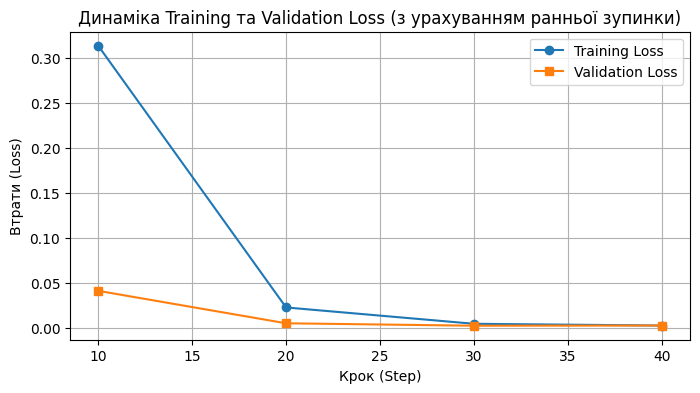

Адаптер успішно збережено в папку: Qwen2.5-SQL-Critic-adapter


In [21]:
import time
import torch
import pandas as pd
import matplotlib.pyplot as plt
from peft import LoraConfig
from trl import SFTConfig, SFTTrainer

peft_config = LoraConfig(
    r=16,
    lora_alpha=32,
    lora_dropout=0.05,
    target_modules="all-linear",
    task_type="CAUSAL_LM",
)

training_args = SFTConfig(
    output_dir="./qwen_sql_critic_results",
    max_length=1024,
    per_device_train_batch_size=2,
    gradient_accumulation_steps=4,
    per_device_eval_batch_size=2,
    learning_rate=2e-4,
    lr_scheduler_type="cosine",
    warmup_steps=5,
    max_steps=40,
    eval_strategy="steps",
    eval_steps=10,
    logging_steps=10,
    fp16=True,
    gradient_checkpointing=True,
    gradient_checkpointing_kwargs={"use_reentrant": False},
    assistant_only_loss=True,
    save_strategy="no",
    report_to="none"
)

trainer = SFTTrainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    processing_class=tokenizer,
    peft_config=peft_config,
)

trainer.model.print_trainable_parameters()

torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()
start_time = time.time()

print("Запуск донавчання LoRA...")
train_result = trainer.train()

train_duration_min = (time.time() - start_time) / 60
peak_gpu_vram_gb = torch.cuda.max_memory_allocated() / (1024**3)

print(f"\nДонавчання успішно завершено за {train_duration_min:.2f} хв.")
print(f"Пікова пам'ять GPU під час тренування: {peak_gpu_vram_gb:.2f} GB")

log_history = trainer.state.log_history

train_losses = {item["step"]: item["loss"] for item in log_history if "loss" in item}
eval_losses = {item["step"]: item["eval_loss"] for item in log_history if "eval_loss" in item}

common_steps = sorted(set(train_losses.keys()).intersection(set(eval_losses.keys())))
df_loss = pd.DataFrame([
    {
        "Step": step,
        "Training Loss": train_losses[step],
        "Validation Loss": eval_losses[step]
    }
    for step in common_steps
])

plt.figure(figsize=(8, 4))
plt.plot(df_loss["Step"], df_loss["Training Loss"], label="Training Loss", marker="o")
plt.plot(df_loss["Step"], df_loss["Validation Loss"], label="Validation Loss", marker="s")
plt.xlabel("Крок (Step)")
plt.ylabel("Втрати (Loss)")
plt.title("Динаміка Training та Validation Loss (з урахуванням ранньої зупинки)")
plt.legend()
plt.grid(True)
plt.show()

adapter_dir = "Qwen2.5-SQL-Critic-adapter"
trainer.save_model(adapter_dir)
print(f"Адаптер успішно збережено в папку: {adapter_dir}")

## 1.5. Порівняння

### Висновки щодо донавчання

**1. Аналіз метрик:**
До донавчання базова модель добре форматувала валідний JSON, але саму задачу не розуміла. Точність еквівалентності була 52.3%, тобто модель просто вгадувала. Після застосування LoRA точність зросла до 99.1%, що означає, що модель навчилася порівнювати SQL-запити.

**2. Якісний аналіз та помилки:**
З виведених прикладів чітко видно проблему базової моделі, вона на всі запити просто відповідала `is_semantically_equivalent: true`.
Після донавчання модель почала помічати відсутність `WHERE` або `GROUP BY` і правильно заповнювати `error_reason`. Залишковий 0.9% помилок, скоріш за все, пов'язаний зі складними JOIN або вкладеними запитами, оскільки датасет генерувався регулярними виразами і міг не покрити всі крайові випадки.

**3. Перевірка загальних знань:**
Адаптер не зламав базові навички моделі:
* **Математика:** Модель правильно рахує, видаючи правильну відповідь.
* **Граматика:** У третьому запиті донавчена модель чітко і без зайвого тексту виправила `have went` на `went` та `buyed` на `bought`.
* **Географічні факти:** Про найглибшу річку обидві моделі згалюцинували назвавши Янцзи, але головне тут те, що після LoRA модель не почала відповідати JSON-ом на звичайні питання і зберегла адекватну текстову структуру.

Отже модель успішно адаптувалася під задачу.

In [22]:
print("Оцінка базової моделі до донавчання...")

with trainer.model.disable_adapter():
    before_metrics, before_raw_results = evaluate(
        trainer.model, tokenizer, test_dataset, eval_system_prompt, batch_size=8
    )

print("Оцінка донавченої моделі після донавчання...")

after_metrics, after_raw_results = evaluate(
    trainer.model, tokenizer, test_dataset, eval_system_prompt, batch_size=8
)

print("Таблиця порівняння метрик:")
df_metrics = pd.DataFrame([before_metrics, after_metrics], index=["до донавчання", "після донавчання"]).T
print(df_metrics.to_string())

print("Якісний аналіз відповідей:")

for i in range(5):
    message = before_raw_results[i][0]
    target = before_raw_results[i][2]
    ans_before = before_raw_results[i][1]
    ans_after = after_raw_results[i][1]

    print(f"\nПриклад №{i+1}:")
    print(f"Вхідний запит:\n{message}\n")
    print(f"Еталон: {target}")
    print(f"Модель ДО: {ans_before}")
    print(f"Модель ПІСЛЯ: {ans_after}")
    print("-" * 70)

print("Перевірка на загальних запитах:")

general_queries = [
    "A boy has 295$, the candy price is 15$. How many candies can he buy?",
    "Which river is the deepest in the world?",
    "Correct the grammar mistakes in this sentence: 'He have went to the store yesterday and buyed milk.'"
]

for i, query in enumerate(general_queries, 1):
    print(f"\nЗапит {i}: {query}")

    chat_prompt = tokenizer.apply_chat_template(
        [{"role": "user", "content": query}],
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = tokenizer(chat_prompt, return_tensors="pt").to(trainer.model.device)

    with trainer.model.disable_adapter():
        out_base = trainer.model.generate(**inputs, max_new_tokens=512, do_sample=False)
        ans_base = tokenizer.decode(out_base[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()

    out_ft = trainer.model.generate(**inputs, max_new_tokens=512, do_sample=False)
    ans_ft = tokenizer.decode(out_ft[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()

    print(f"ДО: {ans_base.replace('\n', ' ')}...")
    print(f"ПІСЛЯ: {ans_ft.replace('\n', ' ')}...")

Оцінка базової моделі до донавчання...
Оцінка донавченої моделі після донавчання...
Таблиця порівняння метрик:
                             до донавчання  після донавчання
Чистий JSON, %                     100.000           100.000
Валідний JSON, %                   100.000           100.000
Точність еквівалентності, %         52.375            99.125
Якісний аналіз відповідей:

Приклад №1:
Вхідний запит:
DDL: CREATE SCHEMA if not exists funding; USE funding; CREATE TABLE if not exists research_funding (id INT, project_id INT, year INT, funding DECIMAL(10, 2)); INSERT INTO research_funding (id, project_id, year, funding) VALUES (1, 1, 2021, 5000000.00), (2, 2, 2020, 3000000.00), (3, 3, 2021, 6000000.00), (4, 4, 2020, 4000000.00);
Original SQL: SELECT SUM(funding) FROM funding.research_funding WHERE year = 2021;
Optimized SQL: SELECT SUM(funding) FROM funding.research_funding ;

Еталон: {'is_semantically_equivalent': False, 'error_reason': 'Missing WHERE filter condition.'}
Модель ДО: 

#### Публікація адаптера на Hugging Face Hub

Авторизація в екосистемі Hugging Face.

In [23]:
notebook_login()

Публікація результатів. Створення нового репозиторію та завантаження до нього ваг натренованого LoRA-адаптера разом із конфігурацією токенізатора.

In [24]:
repo_name = "Hokaigo/Qwen2.5-1.5B-SQL-Critic-LoRA"
trainer.model.push_to_hub(repo_name)
tokenizer.push_to_hub(repo_name)

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...adapter_model.safetensors:   0%|          | 45.7kB / 73.9MB            

Validating                    :           |   0%            

README.md:   0%|          | 0.00/5.17k [00:00<?, ?B/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...mpn_gzpvdc/tokenizer.json: 100%|##########| 11.4MB / 11.4MB            

Validating                    :           |   0%            

CommitInfo(commit_url='https://huggingface.co/Hokaigo/Qwen2.5-1.5B-SQL-Critic-LoRA/commit/0a93f12fb0dc3132c015abc227622c2e7a688ee4', commit_message='Upload tokenizer', commit_description='', oid='0a93f12fb0dc3132c015abc227622c2e7a688ee4', pr_url=None, repo_url=RepoUrl('https://huggingface.co/Hokaigo/Qwen2.5-1.5B-SQL-Critic-LoRA', endpoint='https://huggingface.co', repo_type='model', repo_id='Hokaigo/Qwen2.5-1.5B-SQL-Critic-LoRA'), pr_revision=None, pr_num=None)

**Посилання на завантажений адаптер на Hugging Face Hub:**
[Hokaigo/Qwen2.5-1.5B-SQL-Critic-LoRA](https://huggingface.co/Hokaigo/Qwen2.5-1.5B-SQL-Critic-LoRA)